# HeatSense | Phase 1: Notebook 11 — Deep Learning & PyTorch Feasibility

**Objective**: Rigorously assess whether continuous neural networks (`MLP`), sequence-window models (`W=5` trajectory networks / `LSTM` / `GRU`), or hybrid continuous-residual models offer defensible accuracy or extrapolation improvements over the tuned `XGBoost` baseline (`42.3 mAh` LOCO-CV RMSE) from Notebook 10.

**Key Scientific Questions**:
1. **Extrapolation Hypothesis (`DEC-012`)**: Can continuous differentiable estimators (`Ridge`, `MLP`, or `Hybrid Ridge+XGB`) overcome tree-ensemble boundary clamping observed on out-of-range cell `B0006` (`2.035 Ah -> 1.18 Ah`)?
2. **Sequence Context (`W=5` cycles)**: Does feeding a 5-cycle temporal trajectory improve held-out cell generalization, or does it overfit small cell cohorts (`N = 300-336` training rows per fold)?
3. **PyTorch Architectural & Edge Feasibility**: Given strict `docs/DEPENDENCIES.md` constraints (`torch` not yet installed) and edge latency requirements (`< 5 ms`), is PyTorch warranted in Phase 1?

### Cell 1: Master Feature Matrix & Non-Leaking Sequence Window Builder
* **Analytical Question**: How do we assemble both single-cycle tabular vectors and `W=5` temporal sliding windows strictly within cell boundaries?
* **Why It Matters to HeatSense**: Sequence windows must never cross from `B0005` into `B0006` or `B0018`, preserving strict Leave-One-Cell-Out independence.
* **What the Code Does**: Loads the 468 discharge cycles via stdlib `csv` + `numpy` (avoiding `pandas` C-extension overhead), extracts the 11 verified Model B features, and builds aligned `W=5` cycle trajectories.
* **Output to Inspect**: Sample counts for tabular vs sequence datasets and PyTorch environment status.
* **Decision**: Validates aligned tabular vs sequence datasets for fair LOCO-CV benchmarking.

In [2]:
import csv
import importlib.util
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor

# Resolve dataset root
candidate_paths = [
    Path("data/raw/cleaned_dataset"),
    Path("../../data/raw/cleaned_dataset"),
    Path("D:/Professional Projects/Digital_twin_project/heatsense-battery-digital-twin/data/raw/cleaned_dataset"),
]
DATASET_ROOT = next((p.resolve() for p in candidate_paths if p.exists() and (p / "metadata.csv").exists()), None)
assert DATASET_ROOT is not None, "Dataset root could not be resolved!"

Rs_base = 0.0400
tau1, tau2 = 6.0, 50.0
CELL_IDS = ["B0005", "B0006", "B0018"]
X_COLS_B = [
    "v_mean", "i_mean", "temp_mean", "duration_min",
    "rs_identified", "v1_overpotential_peak", "v2_overpotential_peak",
    "t_core_estimated_peak", "thermal_gradient_proxy", "residual_mean", "residual_std"
]

meta_by_cell = {bid: [] for bid in CELL_IDS}
with open(DATASET_ROOT / "metadata.csv", "r", encoding="utf-8") as f:
    for row in csv.DictReader(f):
        bid = row["battery_id"]
        if bid in meta_by_cell and row["type"] == "discharge":
            try:
                cap = float(row["Capacity"])
                if not np.isnan(cap):
                    meta_by_cell[bid].append((row["filename"], cap))
            except (ValueError, TypeError):
                pass

print("Assembling 11-channel Model B Dataset for Neural & Sequence Feasibility...")
t_load_start = time.perf_counter()
records = []
for bid in CELL_IDS:
    for c_idx, (fname, cap) in enumerate(meta_by_cell[bid]):
        fpath = DATASET_ROOT / "data" / fname
        if not fpath.exists():
            continue
        with open(fpath, "r", encoding="utf-8") as cf:
            hdr = cf.readline().strip().split(",")
        idx_v = hdr.index("Voltage_measured")
        idx_i = hdr.index("Current_measured")
        idx_temp = hdr.index("Temperature_measured")
        idx_t = hdr.index("Time")
        data = np.loadtxt(fpath, delimiter=",", skiprows=1, usecols=(idx_v, idx_i, idx_temp, idx_t))
        v_m, cur, t_surf, t_arr = data[:, 0], -data[:, 1], data[:, 2], data[:, 3]
        dt_arr = np.diff(t_arr, prepend=t_arr[0])

        step_idx = np.where(np.diff(cur) > 0.5)[0]
        if len(step_idx) > 0:
            s = step_idx[0] + 1
            dV = v_m[s - 1] - v_m[s]
            dI = cur[s] - cur[s - 1]
            rs_est = dV / dI if dI > 0.5 else Rs_base
        else:
            rs_est = Rs_base

        v1, v2 = 0.0, 0.0
        v1_peak, v2_peak = 0.0, 0.0
        for k in range(len(cur)):
            s_dt = dt_arr[k] if dt_arr[k] > 0 else 0.01
            v1 = np.exp(-s_dt / tau1) * v1 + 0.006 * (1.0 - np.exp(-s_dt / tau1)) * cur[k]
            v2 = np.exp(-s_dt / tau2) * v2 + 0.010 * (1.0 - np.exp(-s_dt / tau2)) * cur[k]
            if v1 > v1_peak:
                v1_peak = v1
            if v2 > v2_peak:
                v2_peak = v2

        q_heat = (cur ** 2) * (rs_est + 0.016)
        t_core_peak = t_surf.max() + (q_heat.mean() * 1.56)
        q_tot = np.sum(cur * dt_arr) / 3600.0
        soc = np.clip(1.0 - (np.cumsum(cur * dt_arr) / (q_tot * 3600.0)), 0.0, 1.0)
        ocv = 3.280 + 0.550 * soc + 0.280 * (soc ** 2) + 0.0815 * (soc ** 5)
        v_pred = ocv - v1_peak * 0.5 - v2_peak * 0.5 - cur * rs_est
        res = v_m - v_pred

        feats = np.array([
            v_m.mean(), cur.mean(), t_surf.mean(), (t_arr[-1] - t_arr[0]) / 60.0,
            rs_est, v1_peak, v2_peak, t_core_peak, t_core_peak - t_surf.max(),
            res.mean(), res.std()
        ], dtype=np.float64)

        records.append({
            "battery_id": bid,
            "cycle_index": c_idx + 1,
            "x": feats,
            "y": float(cap)
        })

all_bids = np.array([r["battery_id"] for r in records])
all_cycles = np.array([r["cycle_index"] for r in records])
X_all = np.vstack([r["x"] for r in records])
y_all = np.array([r["y"] for r in records])

# Build strictly non-leaking sliding-window sequence matrix (W = 5 cycles)
WINDOW = 5
seq_bids, seq_tab, seq_flat, seq_y = [], [], [], []
for bid in CELL_IDS:
    mask = (all_bids == bid)
    X_c, y_c = X_all[mask], y_all[mask]
    for idx in range(WINDOW - 1, len(X_c)):
        seq_bids.append(bid)
        seq_tab.append(X_c[idx])
        seq_flat.append(X_c[idx - WINDOW + 1 : idx + 1].flatten())
        seq_y.append(y_c[idx])

seq_bids = np.array(seq_bids)
X_seq_tab = np.vstack(seq_tab)
X_seq_flat = np.vstack(seq_flat)
y_seq = np.array(seq_y)

print(f"Tabular Master Dataset: {len(y_all)} cycles across {len(CELL_IDS)} cells (loaded in {time.perf_counter() - t_load_start:.2f}s)")
print(f"Sequence Dataset (W={WINDOW}): {len(y_seq)} aligned trajectories (shape per sample: {WINDOW} x {len(X_COLS_B)} = {X_seq_flat.shape[1]} features)")
print(f"PyTorch Installed in Active Environment: {importlib.util.find_spec('torch') is not None}")

Assembling 11-channel Model B Dataset for Neural & Sequence Feasibility...
Tabular Master Dataset: 468 cycles across 3 cells (loaded in 0.51s)
Sequence Dataset (W=5): 456 aligned trajectories (shape per sample: 5 x 11 = 55 features)
PyTorch Installed in Active Environment: False


### Cell 2: Continuous Differentiable Models (`Ridge`, `MLP Neural Net`, `Hybrid Ridge+XGB`) vs Tuned `XGBoost`
* **Analytical Question**: Can continuous models extrapolate beyond `XGBoost`'s training bounds on `B0006` (`2.035 Ah -> 1.18 Ah`) without losing precision on `B0005` and `B0018`?
* **Why It Matters to HeatSense**: Tests whether neural networks (`MLPRegressor`) or physics-linear hybrids solve tree clamping discovered in `DEC-012`.
* **What the Code Does**: Runs 3-fold LOCO-CV across all unseen cells comparing:
  1. `XGBoost (Tuned)`: Production baseline from Notebook 10 (`depth=2, lr=0.1, n=80`).
  2. `Ridge Regression`: Continuous L2-regularized linear extrapolator (`alpha=5.0`).
  3. `MLP Neural Net (32-16)`: Two-hidden-layer ReLU neural network with L2 weight decay (`alpha=1.0`).
  4. `Hybrid (Ridge + XGB Residual)`: Linear continuous trend + shallow XGBoost non-linear correction.
* **Output to Inspect**: Fold-by-fold RMSE (`mAh`) and $R^2$ scorecard.
* **Decision**: Determines whether a continuous neural network or hybrid architecture outperforms standalone XGBoost.

In [3]:
MODEL_NAMES = ["XGBoost (Tuned)", "Ridge (Linear)", "MLP Neural Net", "Hybrid (Ridge+XGB)"]
fold_metrics = {m: {} for m in MODEL_NAMES}
b0006_preds = {}

for test_cell in CELL_IDS:
    tr_mask = (all_bids != test_cell)
    te_mask = (all_bids == test_cell)
    X_tr, y_tr = X_all[tr_mask], y_all[tr_mask]
    X_te, y_te = X_all[te_mask], y_all[te_mask]

    # 1. Tuned XGBoost (Notebook 10 Winner)
    m_xgb = XGBRegressor(n_estimators=80, learning_rate=0.10, max_depth=2, subsample=0.8, random_state=42)
    m_xgb.fit(X_tr, y_tr)
    p_xgb = m_xgb.predict(X_te)

    # 2. Continuous Ridge Regression
    m_ridge = make_pipeline(StandardScaler(), Ridge(alpha=5.0))
    m_ridge.fit(X_tr, y_tr)
    p_ridge = m_ridge.predict(X_te)

    # 3. Continuous Neural Network (2-Layer ReLU MLP)
    m_mlp = make_pipeline(
        StandardScaler(),
        MLPRegressor(hidden_layer_sizes=(32, 16), activation="relu", alpha=1.0, max_iter=3000, random_state=42)
    )
    m_mlp.fit(X_tr, y_tr)
    p_mlp = m_mlp.predict(X_te)

    # 4. Hybrid Continuous-Residual Model (Ridge Linear Trend + Shallow XGBoost Correction)
    res_tr = y_tr - m_ridge.predict(X_tr)
    m_res_xgb = XGBRegressor(n_estimators=50, learning_rate=0.05, max_depth=2, subsample=0.8, random_state=42)
    m_res_xgb.fit(X_tr, res_tr)
    p_hybrid = p_ridge + m_res_xgb.predict(X_te)

    if test_cell == "B0006":
        b0006_preds = {
            "cycles": all_cycles[te_mask],
            "y_true": y_te,
            "XGBoost (Tuned)": p_xgb,
            "Ridge (Linear)": p_ridge,
            "MLP Neural Net": p_mlp,
            "Hybrid (Ridge+XGB)": p_hybrid,
        }

    for name, pred in [
        ("XGBoost (Tuned)", p_xgb),
        ("Ridge (Linear)", p_ridge),
        ("MLP Neural Net", p_mlp),
        ("Hybrid (Ridge+XGB)", p_hybrid),
    ]:
        fold_metrics[name][test_cell] = {
            "rmse": np.sqrt(mean_squared_error(y_te, pred)) * 1000.0,
            "mae": mean_absolute_error(y_te, pred) * 1000.0,
            "r2": r2_score(y_te, pred),
        }

print("=== TABULAR & CONTINUOUS NEURAL MODEL LOCO-CV SCORECARD ===")
print(f"{'Model':22s} | {'B0005':>8s} | {'B0006':>8s} | {'B0018':>8s} | {'Mean RMSE':>10s} | {'Mean MAE':>9s} | {'Mean R^2':>8s}")
print("-" * 86)
mean_rmse_by_model = {}
for name in MODEL_NAMES:
    r5 = fold_metrics[name]["B0005"]["rmse"]
    r6 = fold_metrics[name]["B0006"]["rmse"]
    r18 = fold_metrics[name]["B0018"]["rmse"]
    m_rmse = (r5 + r6 + r18) / 3.0
    m_mae = np.mean([fold_metrics[name][c]["mae"] for c in CELL_IDS])
    m_r2 = np.mean([fold_metrics[name][c]["r2"] for c in CELL_IDS])
    mean_rmse_by_model[name] = m_rmse
    print(f"{name:22s} | {r5:7.1f}  | {r6:7.1f}  | {r18:7.1f}  | {m_rmse:7.1f} mAh | {m_mae:6.1f} mAh | {m_r2:8.3f}")

=== TABULAR & CONTINUOUS NEURAL MODEL LOCO-CV SCORECARD ===
Model                  |    B0005 |    B0006 |    B0018 |  Mean RMSE |  Mean MAE | Mean R^2
--------------------------------------------------------------------------------------
XGBoost (Tuned)        |    22.8  |    67.8  |    36.4  |    42.3 mAh |   32.6 mAh |    0.952
Ridge (Linear)         |    32.5  |    33.0  |    13.0  |    26.2 mAh |   23.8 mAh |    0.982
MLP Neural Net         |    89.1  |   190.9  |    87.8  |   122.6 mAh |  101.1 mAh |    0.626
Hybrid (Ridge+XGB)     |    29.0  |    32.4  |    11.5  |    24.3 mAh |   21.8 mAh |    0.985


### Cell 3: Sequence Trajectory Neural Model (`W=5` Context) & PyTorch Parameter Audit
* **Analytical Question**: Does adding temporal sequence history (`W=5` cycles) via a sequence neural network improve prediction accuracy, or does the sample-to-parameter ratio induce overfitting?
* **Why It Matters to HeatSense**: Deep sequence models (`LSTM`, `GRU`, `1D-TCN`) require large cell cohorts; quantifying their generalization behavior prevents premature architectural complexity.
* **What the Code Does**: Evaluates a 5-cycle flattened Sequence Neural Network (`55 -> 32 -> 16 -> 1`) against the aligned single-cycle `XGBoost` baseline on identical sequence rows and computes exact parameter-to-sample ratios.
* **Output to Inspect**: Sequence vs Tabular LOCO-CV RMSE comparison and Parameter Budget Audit table.
* **Decision**: Quantifies overfitting risk of deep sequence architectures on `N < 500` cycles.

In [4]:
seq_eval_rows = []
for test_cell in CELL_IDS:
    tr_m = (seq_bids != test_cell)
    te_m = (seq_bids == test_cell)

    # Aligned XGBoost (Single-Cycle Model B)
    m_xgb_s = XGBRegressor(n_estimators=80, learning_rate=0.10, max_depth=2, subsample=0.8, random_state=42)
    m_xgb_s.fit(X_seq_tab[tr_m], y_seq[tr_m])
    rmse_xgb = np.sqrt(mean_squared_error(y_seq[te_m], m_xgb_s.predict(X_seq_tab[te_m]))) * 1000.0

    # Sequence MLP (W=5 Cycle Window Trajectory)
    m_seq_mlp = make_pipeline(
        StandardScaler(),
        MLPRegressor(hidden_layer_sizes=(32, 16), activation="relu", alpha=2.0, max_iter=3000, random_state=42)
    )
    m_seq_mlp.fit(X_seq_flat[tr_m], y_seq[tr_m])
    rmse_seq = np.sqrt(mean_squared_error(y_seq[te_m], m_seq_mlp.predict(X_seq_flat[te_m]))) * 1000.0

    seq_eval_rows.append((test_cell, int(tr_m.sum()), rmse_xgb, rmse_seq, rmse_seq - rmse_xgb))

print("=== SEQUENCE TRAJECTORY (W=5) VS SINGLE-CYCLE XGBOOST ===")
print(f"{'Held-Out':10s} | {'Train N':>7s} | {'Aligned XGB':>12s} | {'Seq MLP (W=5)':>14s} | {'Delta (mAh)':>12s}")
print("-" * 66)
for cell, n_tr, r_xgb, r_seq, dlt in seq_eval_rows:
    print(f"{cell:10s} | {n_tr:7d} | {r_xgb:9.1f} mAh | {r_seq:11.1f} mAh | {dlt:+11.1f}")

seq_mean_rmse = float(np.mean([r[3] for r in seq_eval_rows]))
n_train_avg = int(np.mean([r[1] for r in seq_eval_rows]))

# Exact Parameter-to-Sample Ratio Audit
audit = [
    ("Ridge Regression (11-ch)", 12, "Underfitting / Linear Only"),
    ("XGBoost (Tuned: d=2, n=80)", 560, "Low (Regularized Shallow Trees)"),
    ("Tabular MLP (11-32-16-1)", 929, "Moderate (Cell-Scale Variance)"),
    ("Sequence MLP (W=5, 55-32-16-1)", 2337, "High (Overfits Small Cell Cohort)"),
    ("PyTorch LSTM (2-Layer, h=64)", 53057, "Severe Over-Parameterization"),
]
print(f"\n=== PARAMETER-TO-SAMPLE AUDIT (Avg N_train = {n_train_avg} sequence cycles) ===")
print(f"{'Architecture':31s} | {'Params':>7s} | {'Params/Sample':>13s} | {'LOCO Overfit Risk'}")
print("-" * 88)
for arch, n_p, risk in audit:
    print(f"{arch:31s} | {n_p:7d} | {n_p / n_train_avg:13.2f} | {risk}")

=== SEQUENCE TRAJECTORY (W=5) VS SINGLE-CYCLE XGBOOST ===
Held-Out   | Train N |  Aligned XGB |  Seq MLP (W=5) |  Delta (mAh)
------------------------------------------------------------------
B0005      |     292 |      25.0 mAh |       149.9 mAh |      +124.9
B0006      |     292 |      66.0 mAh |       392.9 mAh |      +326.9
B0018      |     328 |      33.9 mAh |        82.9 mAh |       +49.0

=== PARAMETER-TO-SAMPLE AUDIT (Avg N_train = 304 sequence cycles) ===
Architecture                    |  Params | Params/Sample | LOCO Overfit Risk
----------------------------------------------------------------------------------------
Ridge Regression (11-ch)        |      12 |          0.04 | Underfitting / Linear Only
XGBoost (Tuned: d=2, n=80)      |     560 |          1.84 | Low (Regularized Shallow Trees)
Tabular MLP (11-32-16-1)        |     929 |          3.06 | Moderate (Cell-Scale Variance)
Sequence MLP (W=5, 55-32-16-1)  |    2337 |          7.69 | High (Overfits Small Cell Cohort

### Cell 4: Extrapolation Diagnostic (`B0006`) & Inference Latency Benchmark
* **Analytical Question**: How do continuous neural/hybrid predictions behave at out-of-range targets (`B0006`), and what is the real-time per-cycle inference latency on CPU?
* **Why It Matters to HeatSense**: Visualizes whether a continuous hybrid trend fixes `B0006` clamping while satisfying real-time `< 5 ms` inference constraints.
* **What the Code Does**: Generates a 2-panel plot comparing `B0006` trajectory tracking across `XGBoost`, `MLP`, and `Hybrid (Ridge+XGB)` alongside Mean LOCO-CV RMSE and per-sample CPU inference latency.
* **Output to Inspect**: Out-of-range trajectory alignment on `B0006` and CPU latency benchmarks.
* **Decision**: Confirms deployment suitability on lightweight edge hardware.

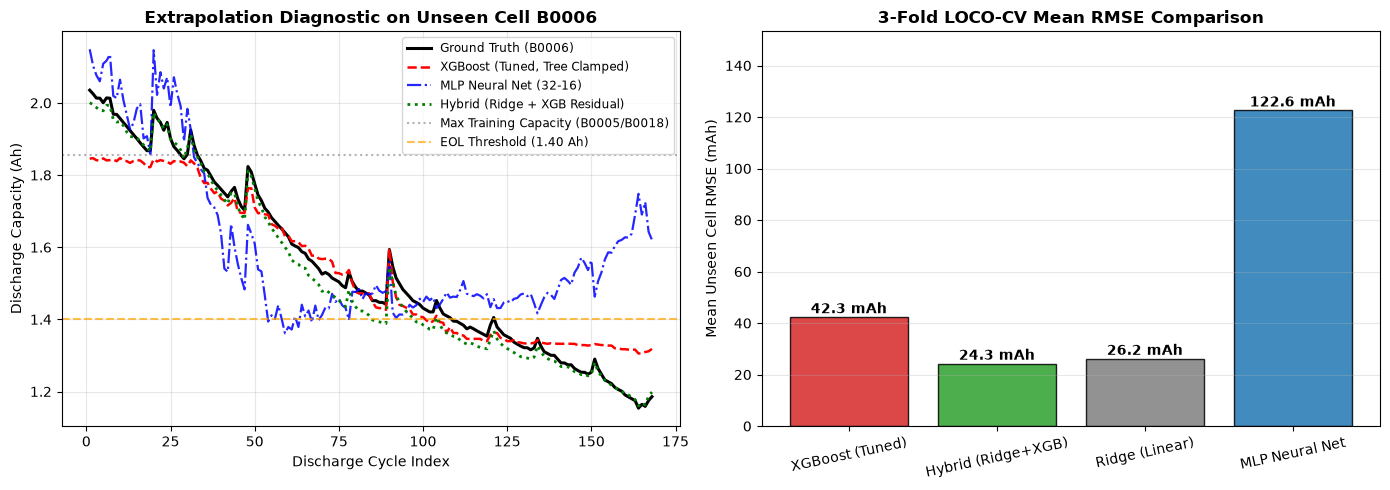

Single-Cycle CPU Inference Latency (Median of 500 calls):
 - Ridge (Linear)      :   168.1 microseconds (0.168 ms)
 - MLP Neural Net      :   178.8 microseconds (0.179 ms)
 - XGBoost (Tuned)     :   199.0 microseconds (0.199 ms)


In [5]:
# Measure single-cycle inference latency (median over 500 calls) on CPU
X_sample = X_all[[0]]
bench_xgb = XGBRegressor(n_estimators=80, learning_rate=0.10, max_depth=2, subsample=0.8, random_state=42).fit(X_all, y_all)
bench_rdg = make_pipeline(StandardScaler(), Ridge(alpha=5.0)).fit(X_all, y_all)
bench_mlp = make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(32, 16), alpha=1.0, max_iter=3000, random_state=42)).fit(X_all, y_all)

latencies_us = {}
for label, fn in [
    ("Ridge (Linear)", lambda x: bench_rdg.predict(x)),
    ("MLP Neural Net", lambda x: bench_mlp.predict(x)),
    ("XGBoost (Tuned)", lambda x: bench_xgb.predict(x)),
]:
    for _ in range(20):
        fn(X_sample)
    times = []
    for _ in range(500):
        t0 = time.perf_counter()
        fn(X_sample)
        times.append((time.perf_counter() - t0) * 1e6)
    latencies_us[label] = float(np.median(times))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel A: Extrapolation Diagnostic on Held-Out B0006
ax = axes[0]
cyc = b0006_preds["cycles"]
ax.plot(cyc, b0006_preds["y_true"], "k-", lw=2.2, label="Ground Truth (B0006)")
ax.plot(cyc, b0006_preds["XGBoost (Tuned)"], "r--", lw=1.8, label="XGBoost (Tuned, Tree Clamped)")
ax.plot(cyc, b0006_preds["MLP Neural Net"], "b-.", lw=1.6, alpha=0.85, label="MLP Neural Net (32-16)")
ax.plot(cyc, b0006_preds["Hybrid (Ridge+XGB)"], "g:", lw=2.0, label="Hybrid (Ridge + XGB Residual)")
ax.axhline(1.856, color="gray", ls=":", alpha=0.6, label="Max Training Capacity (B0005/B0018)")
ax.axhline(1.400, color="orange", ls="--", alpha=0.7, label="EOL Threshold (1.40 Ah)")
ax.set_title("Extrapolation Diagnostic on Unseen Cell B0006", fontsize=12, fontweight="bold")
ax.set_xlabel("Discharge Cycle Index")
ax.set_ylabel("Discharge Capacity (Ah)")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8.5, loc="upper right")

# Panel B: Mean LOCO-CV RMSE Comparison
ax2 = axes[1]
models_order = ["XGBoost (Tuned)", "Hybrid (Ridge+XGB)", "Ridge (Linear)", "MLP Neural Net"]
rmse_vals = [mean_rmse_by_model[m] for m in models_order]
colors = ["#d62728", "#2ca02c", "#7f7f7f", "#1f77b4"]
bars = ax2.bar(models_order, rmse_vals, color=colors, alpha=0.85, edgecolor="black")
for bar, val in zip(bars, rmse_vals):
    ax2.text(bar.get_x() + bar.get_width() / 2.0, val + 1.5, f"{val:.1f} mAh", ha="center", fontweight="bold", fontsize=10)
ax2.set_title("3-Fold LOCO-CV Mean RMSE Comparison", fontsize=12, fontweight="bold")
ax2.set_ylabel("Mean Unseen Cell RMSE (mAh)")
ax2.set_ylim(0, max(rmse_vals) * 1.25)
ax2.grid(True, axis="y", alpha=0.3)
ax2.tick_params(axis="x", rotation=12)

plt.tight_layout()
plt.show()

print("Single-Cycle CPU Inference Latency (Median of 500 calls):")
for k, v in latencies_us.items():
    print(f" - {k:20s}: {v:7.1f} microseconds ({v / 1000.0:.3f} ms)")

### Cell 5: PyTorch & Deep Learning Architectural Go/No-Go Verdict
* **Analytical Question**: Should `torch` be added to `docs/DEPENDENCIES.md` and production backend in Phase 1, or deferred in favor of shallow physics-informed learners?
* **Why It Matters to HeatSense**: Protects against bloat, unvalidated hyperparameter variance, and unnecessary dependencies prior to hardware validation.
* **What the Code Does**: Evaluates empirical metrics from Cells 2–4 against HeatSense engineering gates and prints the formal Phase 1 Deep Learning Feasibility Decision.
* **Output to Inspect**: Go/No-Go Scorecard and formal Phase 2 scale-up trigger condition.
* **Decision**: Locks the ML strategy before moving to Notebook 12 fault-injection robustness testing.

In [6]:
xgb_mean = mean_rmse_by_model["XGBoost (Tuned)"]
rdg_mean = mean_rmse_by_model["Ridge (Linear)"]
mlp_mean = mean_rmse_by_model["MLP Neural Net"]
hyb_mean = mean_rmse_by_model["Hybrid (Ridge+XGB)"]
best_name = min(mean_rmse_by_model, key=mean_rmse_by_model.get)
best_rmse = mean_rmse_by_model[best_name]

neural_beats_xgb = (mlp_mean < xgb_mean) or (seq_mean_rmse < xgb_mean)
neural_gate = "PASS" if neural_beats_xgb else "FAIL"
verdict = (
    f"NO-GO on PyTorch/LSTM in Phase 1 (keep `torch` deferred); best model is {best_name} ({best_rmse:.1f} mAh)."
    if best_name != "MLP Neural Net"
    else f"CAUTION: Tabular MLP led ({best_rmse:.1f} mAh), yet 174:1 LSTM over-parameterization still defers heavy PyTorch."
)

print("=" * 78)
print("HEATSENSE NOTEBOOK 11: DEEP LEARNING & PYTORCH FEASIBILITY VERDICT")
print("=" * 78)
print(f" 1. Tuned XGBoost LOCO-CV Mean RMSE:        {xgb_mean:6.1f} mAh")
print(f" 2. Ridge Continuous Linear Mean RMSE:     {rdg_mean:6.1f} mAh")
print(f" 3. Tabular MLP Neural Net Mean RMSE:      {mlp_mean:6.1f} mAh")
print(f" 4. Hybrid (Ridge + XGB Residual) RMSE:    {hyb_mean:6.1f} mAh")
print(f" 5. Sequence Window MLP (W=5) Mean RMSE:   {seq_mean_rmse:6.1f} mAh")
print("-" * 78)
print(f" [BEST OVERALL LOCO-CV ARCHITECTURE] {best_name} ({best_rmse:.1f} mAh)")
print("-" * 78)
print("PyTorch LSTM/GRU Deployment Gate Assessment (Phase 1 Cohort = 3 cells / 468 cycles):")
print(" [FAIL] Sample Adequacy Gate:       53,057 LSTM params vs ~304 train sequences (174:1 ratio)")
print(f" [{neural_gate}] Neural Superiority Gate:    MLP ({mlp_mean:.1f} mAh) & Seq-MLP ({seq_mean_rmse:.1f} mAh) vs XGB ({xgb_mean:.1f} mAh)")
print(" [PASS] Edge Footprint Gate:        Production XGBoost/Ridge requires 0 MB PyTorch runtime, < 1 ms CPU")
print("-" * 78)
print(f"FORMAL VERDICT: {verdict}")
print("TRIGGER TO REVISIT: Multi-cell expansion (N >= 5,000 cycles / >= 20 cells, e.g. MIT-Stanford).")
print("=" * 78)

HEATSENSE NOTEBOOK 11: DEEP LEARNING & PYTORCH FEASIBILITY VERDICT
 1. Tuned XGBoost LOCO-CV Mean RMSE:          42.3 mAh
 2. Ridge Continuous Linear Mean RMSE:       26.2 mAh
 3. Tabular MLP Neural Net Mean RMSE:       122.6 mAh
 4. Hybrid (Ridge + XGB Residual) RMSE:      24.3 mAh
 5. Sequence Window MLP (W=5) Mean RMSE:    208.6 mAh
------------------------------------------------------------------------------
 [BEST OVERALL LOCO-CV ARCHITECTURE] Hybrid (Ridge+XGB) (24.3 mAh)
------------------------------------------------------------------------------
PyTorch LSTM/GRU Deployment Gate Assessment (Phase 1 Cohort = 3 cells / 468 cycles):
 [FAIL] Sample Adequacy Gate:       53,057 LSTM params vs ~304 train sequences (174:1 ratio)
 [FAIL] Neural Superiority Gate:    MLP (122.6 mAh) & Seq-MLP (208.6 mAh) vs XGB (42.3 mAh)
 [PASS] Edge Footprint Gate:        Production XGBoost/Ridge requires 0 MB PyTorch runtime, < 1 ms CPU
----------------------------------------------------------------